In [1]:
#import sklearn.datasets as datasets
#from sklearn.preprocessing import MinMaxScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#plt.style.use('dark_background')

import simulate_classes as sim

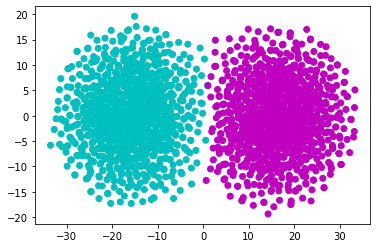

In [2]:
#Make dataset with underlying structure

n_cells = 2000
n_classes = 2 
n_genes = 200
n_informative = 4

#X, y = datasets.make_classification(n_samples=n_cells, n_features=n_genes, n_informative=n_informative, n_classes=n_classes, shift=1)

means, variances = sim.generate_means(n_genes, n_informative)
X, y = sim.generate_data(n_cells, n_genes, n_classes, means, variances)

sim.visualize_clusters(X, y, n_classes, filename='../results/data_embedding.pdf')

# Make spatial patterns

# Set image dimensions
x_max = 500
y_max = 500 



## Case 1

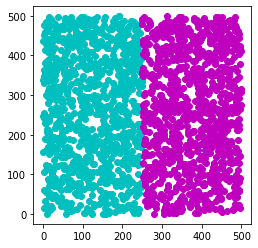

In [4]:
n_typeA = np.where(y == 0)[0].shape[0]
n_typeB = np.where(y == 1)[0].shape[0]

typeA_x = np.random.randint(0, x_max/2, size = (n_typeA, 1))
typeA_y = np.random.randint(0, y_max, size = (n_typeA, 1))
A_locs = np.concatenate([typeA_x, typeA_y], axis=1)

typeB_x = np.random.randint(x_max/2, x_max, size = (n_typeB, 1))
typeB_y = np.random.randint(0, y_max, size = (n_typeB, 1))
B_locs = np.concatenate([typeB_x, typeB_y], axis=1)

A_idx, = np.where(y==0)
B_idx, = np.where(y==1)

# Visualize pattern
fig, ax = plt.subplots()
ax.scatter(A_locs[:, 0], A_locs[:, 1], c='c')
ax.scatter(B_locs[:, 0], B_locs[:, 1], c='m')
ax.set_aspect('equal')
plt.savefig('../results/case1.pdf')
plt.show()

In [5]:
# need to put the data in the same index order as the locs. 

locs = np.zeros((n_cells, 2))

for i in range(0, len(A_idx)):
    j = A_idx[i]
    locs[j, :] = A_locs[i, :]

for i in range(0, len(B_idx)):
    j = B_idx[i]
    locs[j, :] = B_locs[i, :]

loc_df = pd.DataFrame(locs, columns=['x', 'y'])

# export data for calico comparison

gene_names = ['gene_' + str(i) for i in range(1, n_genes + 1)]

X_df = pd.DataFrame(X, columns=gene_names)
bool_arr = [True for x in range(0, len(X_df))]
export_df = pd.concat([loc_df['x'], loc_df['y'], pd.DataFrame(bool_arr, columns=['anchor']), X_df], axis = 1)
export_df.to_csv('../data/simulated/Case1_GeneExpression_Pos.csv')
pd.DataFrame(y, columns = ['cell_type']).to_csv('../data/simulated/Case1_TypeAssignments.csv')

### Run SLDA

In [2]:
import scanpy as sc
import numpy as np
import pandas as pd
from glob import glob
import torch

from model import VAE, loss
from utils import EarlyStop
import torch.nn.functional as F
import os, time, tqdm

from sklearn.neighbors import NearestNeighbors
from scipy import spatial
import spatialdata_preprocessing
import slda 

In [7]:
test_frac = 0.15
#test_size = int(np.round(test_frac * puck_data.X.shape[0]))
test_size = int(np.round(test_frac * X.shape[0]))
#data = torch.tensor(puck_data.X, dtype=torch.float32)a
data = torch.tensor(X, dtype=torch.float32)
dataset = torch.utils.data.TensorDataset(data)
test_data, train_data = torch.utils.data.random_split(dataset, [test_size, data.shape[0]-test_size])

batch_size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size = batch_size, shuffle = True)

In [8]:
points = spatialdata_preprocessing.make_points_arr(loc_df, 'x', 'y')
distance_matrix = spatial.distance.cdist(points, points)

# Constant model params
vocab_size = 5 #best = [75,5,20,50]
n_topics = 2
sigma = 50
n_docs = 200
n_imgs = 1

alpha = torch.ones((n_topics,))/n_topics #uniform priors
beta = torch.ones(vocab_size)/vocab_size

ids = np.zeros((points.shape[0],1))
c = np.concatenate([ids, points], axis=1)

document_locs, docs_in_img = slda.initialize_documents_spatialdata(c, n_docs, n_imgs) #I think this makes sense to fix across training epochs?

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

n_genes = X.shape[1]
latent_size = 2
net = VAE((1, n_genes), latent_size = latent_size)
net.to(device)

lr = 0.02 #set VAE learning rate

In [10]:
PATH_TO_MODELS = '../results'
DATASET_NAME = 'simulatedScaled07Sep'
EXPERIMENT_NAME = 'Case1'

save_name = '_'.join((f'{PATH_TO_MODELS}/{DATASET_NAME}_{EXPERIMENT_NAME}',
                                f'latentDim={latent_size}',
                                f'lr={lr}',
                                f'topics={n_topics}',
                                f'docs={n_docs}',
                                f'vocab={vocab_size}',
                                f'sigma={sigma}')) + '.pt'

In [11]:
loss_tracker = []

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, net.parameters()), lr=lr, weight_decay = 0.0001)

def adjust_lr(optimizer, decay_rate=0.95):
    for param_group in optimizer.param_groups:
        param_group['lr'] *= decay_rate

retrain = True
'''if os.path.exists(save_name):
    print("Model parameters have already been trained before. Retrain ? (y/n)")
    ans = input()
    if not (ans == 'y'):
        checkpoint = torch.load(save_name, map_location = device)
        net.load_state_dict(checkpoint["net"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        for g in optimizer.param_groups:
            g['lr'] = lr
'''
max_epochs = 20
slda_loss = 0 # Set the initial SLDA loss. 
early_stop = EarlyStop(patience = 20, save_name = save_name)
net = net.to(device)

print("training on ", device)
for epoch in range(max_epochs):

    train_loss, n, start = 0.0, 0, time.time()
    
    for jj in range(0, 5):
        for X, in tqdm.tqdm(train_loader, ncols = 50):
        #for X, in train_loader:
            X = X.to(device)
            X_hat, mean, logvar = net(X)

            l = loss(X, X_hat, mean, logvar, slda_loss).to(device)
            optimizer.zero_grad()
            l.backward()
            optimizer.step()

            train_loss += l.cpu().item()
            n += X.shape[0]

        train_loss /= n

    #NOW NEED TO USE THIS PARAMETER SETTING TO DO SLDA...

    #ENCODE DATASET WITH PARTIALLY TRAINED VAE
    decoded_z, mean, logvar = net.forward(data) #embed to latent distrobution
    X_temp = net.sampling(mean, logvar)           #sample within latent distrib

    #USE EMBEDDED DATA TO RUN SLDA 

    #Setup here will have to happen every time :/ 
    featurized_data = spatialdata_preprocessing.calculate_weighted_markers(distance_matrix, X_temp.detach().numpy(), sigma=sigma)
    kmeans, assignments = spatialdata_preprocessing.cluster_descriptors(featurized_data, vocab_size)
    input_arr = slda.build_input_word_array(assignments, c)
    
    
    z, docs, n_dk, n_kw, n_d, n_k = slda.initialize_model(input_arr, n_imgs, n_docs, n_topics, vocab_size)
   

    pi_hat, phi_hat, n_dk, n_kw, n_k, n_d, docs, z, slda_loss = slda.train_model(input_arr, document_locs, docs_in_img, n_imgs, n_docs, n_topics, vocab_size, z, docs, n_dk, n_kw, n_d, n_k, alpha, beta, sigma, n_epochs=10, return_loss=True) #train the SLDA, need to add in a return of the final loss here. 

    
    print('epoch %d, train loss %.4f , time %.1f sec'
          % (epoch, train_loss, time.time() - start))
    
    loss_tracker.append(train_loss)
    adjust_lr(optimizer)
    
    if (early_stop(train_loss, net, optimizer)):
        break

checkpoint = torch.load(early_stop.save_name)
net.load_state_dict(checkpoint["net"])

training on  cpu


100%|█████████████| 14/14 [00:00<00:00, 50.83it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 4.662425994873047
1 4.639985084533691
2 4.305602073669434
3 3.5126466751098633
4 2.9177591800689697
5 2.8847532272338867
6 2.9549403190612793
7 2.936589241027832
8 2.9662318229675293
9 2.9654526710510254
epoch 0, train loss -199741.9291 , time 12.4 sec


100%|█████████████| 14/14 [00:00<00:00, 45.91it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 4.600229740142822
1 4.560959339141846
2 4.184870719909668
3 3.2511672973632812
4 2.89778995513916
5 2.8810558319091797
6 2.945530891418457
7 2.9423675537109375
8 2.969045400619507
9 2.9658689498901367
epoch 1, train loss -199742.4624 , time 12.4 sec


100%|█████████████| 14/14 [00:00<00:00, 55.21it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


... (32 outputs left out)

0 4.1587748527526855
1 3.9615960121154785
2 3.49391508102417
3 2.764854907989502
4 2.6039133071899414
5 2.590447187423706
6 2.643742799758911
7 2.659419536590576
8 2.6418914794921875
9 2.624579906463623
epoch 18, train loss -199745.6516 , time 12.2 sec
EarlyStopping counter: 2 out of 20


100%|█████████████| 14/14 [00:00<00:00, 52.71it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 4.532762050628662
1 4.515787601470947
2 4.311278343200684
3 3.3526692390441895
4 2.9069650173187256
5 2.90468168258667
6 2.9403083324432373
7 2.9255332946777344
8 3.013169288635254
9 2.983447313308716
epoch 19, train loss -199745.7904 , time 12.1 sec


<All keys matched successfully>

Text(0, 0.5, 'loss')

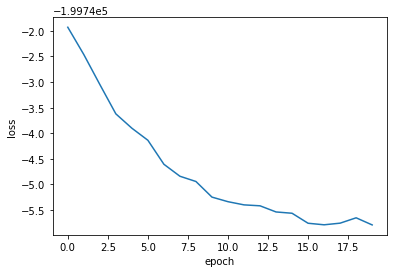

In [12]:
x = [i for i in range(0, len(loss_tracker))]

plt.plot(x, loss_tracker)
plt.xlabel('epoch')
plt.ylabel('loss')

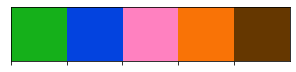

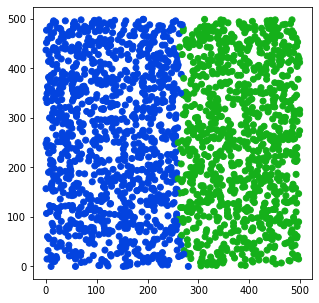

In [13]:
topic_probs, best_topic = slda.get_topic_assignments(phi_hat, pi_hat, document_locs, input_arr, n_docs, c, assignments, sigma, n_topics)
val, count = torch.unique(best_topic, return_counts=True)

colors = ['#15b01a','#0343df', '#ff81c0', '#f97306', '#653700']
color_dict = dict(zip(val.tolist(), colors))
color_assigments = [color_dict[j] for j in best_topic.tolist()]

import seaborn as sns 
sns.palplot(colors)
fig_name = '_'.join((f'{PATH_TO_MODELS}/{DATASET_NAME}_{EXPERIMENT_NAME}',
                                f'latentDim={latent_size}',
                                f'lr={lr}',
                                f'topics={n_topics}',
                                f'docs={n_docs}',
                                f'vocab={vocab_size}',
                                f'sigma={sigma}')) + '.pdf'

fig, ax = plt.subplots(1,1, figsize=(5,5))
ax.scatter(x=points[:, 0], y = points[:, 1], c=color_assigments)
plt.savefig(fig_name)
plt.show()

In [39]:
loc_df['model_topic'] = best_topic
loc_df['ground_truth'] = y
loc_df['renamed_model_topic'] = np.where(best_topic==1, 0, 1)
loc_df.head()

,x,y,model_topic,ground_truth,renamed_model_topic
0,182.0,249.0,1.0,0,0
1,48.0,197.0,1.0,0,0
2,80.0,482.0,1.0,0,0
3,189.0,243.0,1.0,0,0
4,169.0,122.0,1.0,0,0


In [43]:
np.sum(np.equal(loc_df['ground_truth'], loc_df['renamed_model_topic']))/n_cells

0.97

## Case 2 - Third cell type everywhere

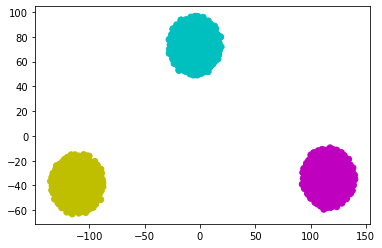

In [3]:
#Make dataset with underlying structure

n_cells = 3000  
n_classes = 3 
n_genes = 200
n_informative = 20

means, variances = sim.generate_means(n_genes, n_informative)
X, y = sim.generate_data(n_cells, n_genes, n_classes, means, variances)

sim.visualize_clusters(X, y, n_classes, filename='../results/case2_data_embedding.pdf')

# Make spatial patterns

# Set image dimensions
x_max = 500
y_max = 500



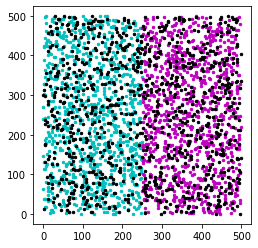

In [4]:
n_typeA = np.where(y == 0)[0].shape[0]
n_typeB = np.where(y == 1)[0].shape[0]
n_typeC = np.where(y == 2)[0].shape[0] #these go everywhere

typeA_x = np.random.randint(0, x_max/2, size = (n_typeA, 1))
typeA_y = np.random.randint(0, y_max, size = (n_typeA, 1))
A_locs = np.concatenate([typeA_x, typeA_y], axis=1)

typeB_x = np.random.randint(x_max/2, x_max, size = (n_typeB, 1))
typeB_y = np.random.randint(0, y_max, size = (n_typeB, 1))
B_locs = np.concatenate([typeB_x, typeB_y], axis=1)

typeC_x = np.random.randint(0, x_max, size = (n_typeC, 1))
typeC_y = np.random.randint(0, y_max, size = (n_typeC, 1))
C_locs = np.concatenate([typeC_x, typeC_y], axis=1)

A_idx, = np.where(y==0)
B_idx, = np.where(y==1)
C_idx, = np.where(y==2)

# Visualize pattern
fig, ax = plt.subplots()
ax.scatter(A_locs[:, 0], A_locs[:, 1], c='c', s=6)
ax.scatter(B_locs[:, 0], B_locs[:, 1], c='m', s=6)
ax.scatter(C_locs[:, 0], C_locs[:, 1], c='k', s=6)
ax.set_aspect('equal')
plt.savefig('../results/case2.pdf')
plt.show()

In [5]:
# need to put the data in the same index order as the locs. 

locs = np.zeros((n_cells, 2))

for i in range(0, len(A_idx)):
    j = A_idx[i]
    locs[j, :] = A_locs[i, :]

for i in range(0, len(B_idx)):
    j = B_idx[i]
    locs[j, :] = B_locs[i, :]

for i in range(0, len(C_idx)):
    j = C_idx[i]
    locs[j, :] = C_locs[i, :]
loc_df = pd.DataFrame(locs, columns=['x', 'y'])

# export data for calico comparison

gene_names = ['gene_' + str(i) for i in range(1, n_genes + 1)]

X_df = pd.DataFrame(X, columns=gene_names)
bool_arr = [True for x in range(0, len(X_df))]
export_df = pd.concat([loc_df['x'], loc_df['y'], pd.DataFrame(bool_arr, columns=['anchor']), X_df], axis = 1)
export_df.to_csv('../data/simulated/Case2_GeneExpression_Pos.csv')
pd.DataFrame(y, columns = ['cell_type']).to_csv('../data/simulated/Case2_TypeAssignments.csv')


In [6]:
test_frac = 0.15
#test_size = int(np.round(test_frac * puck_data.X.shape[0]))
test_size = int(np.round(test_frac * X.shape[0]))
#data = torch.tensor(puck_data.X, dtype=torch.float32)a
data = torch.tensor(X, dtype=torch.float32)
dataset = torch.utils.data.TensorDataset(data)
test_data, train_data = torch.utils.data.random_split(dataset, [test_size, data.shape[0]-test_size])

batch_size = 64
train_loader = torch.utils.data.DataLoader(train_data, batch_size = batch_size, shuffle = True)

In [7]:
points = spatialdata_preprocessing.make_points_arr(loc_df, 'x', 'y')
distance_matrix = spatial.distance.cdist(points, points)

# Constant model params
vocab_size = 5 #best = [75,5,20,50]
n_topics = 2
sigma = 100
n_docs = 200
n_imgs = 1

alpha = torch.ones((n_topics,))/n_topics #uniform priors
beta = torch.ones(vocab_size)/vocab_size

ids = np.zeros((points.shape[0],1))
c = np.concatenate([ids, points], axis=1)

document_locs, docs_in_img = slda.initialize_documents_spatialdata(c, n_docs, n_imgs) #I think this makes sense to fix across training epochs?

In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

n_genes = X.shape[1]
latent_size= 12
net = VAE((1, n_genes), latent_size = latent_size)
net.to(device)

lr = 0.02 #set VAE learning rate

In [10]:
PATH_TO_MODELS = '../results'
DATASET_NAME = 'simulated200'
EXPERIMENT_NAME = 'Case2_07Sep'

save_name = '_'.join((f'{PATH_TO_MODELS}/{DATASET_NAME}_{EXPERIMENT_NAME}',
                                f'latentDim={latent_size}',
                                f'lr={lr}',
                                f'topics={n_topics}',
                                f'docs={n_docs}',
                                f'vocab={vocab_size}',
                                f'sigma={sigma}')) + '.pt'


In [12]:
loss_tracker = []

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, net.parameters()), lr=lr, weight_decay = 0.0001)

def adjust_lr(optimizer, decay_rate=0.95):
    for param_group in optimizer.param_groups:
        param_group['lr'] *= decay_rate

retrain = True
if os.path.exists(save_name):
    print("Model parameters have already been trained before. Retrain ? (y/n)")
    ans = input()
    if not (ans == 'y'):
        checkpoint = torch.load(save_name, map_location = device)
        net.load_state_dict(checkpoint["net"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        for g in optimizer.param_groups:
            g['lr'] = lr

max_epochs = 20
slda_loss = 0 # Set the initial SLDA loss. 
early_stop = EarlyStop(patience = 20, save_name = save_name)
net = net.to(device)

print("training on ", device)
for epoch in range(max_epochs):

    train_loss, n, start = 0.0, 0, time.time()
    
    for jj in range(0, 5):
        for X, in tqdm.tqdm(train_loader, ncols = 50):
        #for X, in train_loader:
            X = X.to(device)
            X_hat, mean, logvar = net(X)

            l = loss(X, X_hat, mean, logvar, slda_loss).to(device)
            optimizer.zero_grad()
            l.backward()
            optimizer.step()

            train_loss += l.cpu().item()
            n += X.shape[0]

        train_loss /= n

    #NOW NEED TO USE THIS PARAMETER SETTING TO DO SLDA...

    #ENCODE DATASET WITH PARTIALLY TRAINED VAE
    decoded_z, mean, logvar = net.forward(data) #embed to latent distrobution
    X_temp = net.sampling(mean, logvar)           #sample within latent distrib

    #USE EMBEDDED DATA TO RUN SLDA 

    #Setup here will have to happen every time :/ 
    featurized_data = spatialdata_preprocessing.calculate_weighted_markers(distance_matrix, X_temp.detach().numpy(), sigma=sigma)
    kmeans, assignments = spatialdata_preprocessing.cluster_descriptors(featurized_data, vocab_size)
    input_arr = slda.build_input_word_array(assignments, c)
    
    
    z, docs, n_dk, n_kw, n_d, n_k = slda.initialize_model(input_arr, n_imgs, n_docs, n_topics, vocab_size)
   

    pi_hat, phi_hat, n_dk, n_kw, n_k, n_d, docs, z, slda_loss = slda.train_model(input_arr, document_locs, docs_in_img, n_imgs, n_docs, n_topics, vocab_size, z, docs, n_dk, n_kw, n_d, n_k, alpha, beta, sigma, n_epochs=10, return_loss=True) #train the SLDA, need to add in a return of the final loss here. 

    
    print('epoch %d, train loss %.4f , time %.1f sec'
          % (epoch, train_loss, time.time() - start))
    
    loss_tracker.append(train_loss)
    adjust_lr(optimizer)
    
    if (early_stop(train_loss, net, optimizer)):
        break

checkpoint = torch.load(early_stop.save_name)
net.load_state_dict(checkpoint["net"])

training on  cpu


100%|█████████████| 40/40 [00:00<00:00, 60.52it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 4.715150356292725
1 4.622160911560059
2 4.34691047668457
3 3.6207211017608643
4 3.2862887382507324
5 3.2543065547943115
6 3.20579195022583
7 3.2286853790283203
8 3.3006913661956787
9 3.3154618740081787
epoch 0, train loss -189530.3636 , time 21.4 sec


100%|█████████████| 40/40 [00:00<00:00, 57.99it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 4.800804615020752
1 4.798823833465576
2 4.764036655426025
3 4.461523056030273
4 3.7159202098846436
5 3.3037261962890625
6 3.216928005218506
7 3.2567081451416016
8 3.2616446018218994
9 3.280956268310547
epoch 1, train loss -189531.5330 , time 21.0 sec


100%|█████████████| 40/40 [00:00<00:00, 59.71it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


... (32 outputs left out)

0 4.862905979156494
1 4.859587669372559
2 4.806009769439697
3 4.454249382019043
4 3.6929843425750732
5 3.35085129737854
6 3.325975179672241
7 3.2752957344055176
8 3.3635144233703613
9 3.3301467895507812
epoch 18, train loss -189533.3309 , time 22.9 sec


100%|█████████████| 40/40 [00:00<00:00, 62.12it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 4.563600063323975
1 4.5282111167907715
2 4.366184711456299
3 3.7360777854919434
4 3.173449993133545
5 3.0323143005371094
6 3.0441653728485107
7 3.05082631111145
8 3.097663402557373
9 3.083216667175293
epoch 19, train loss -189533.2408 , time 21.7 sec
EarlyStopping counter: 1 out of 20


<All keys matched successfully>

Text(0, 0.5, 'loss')

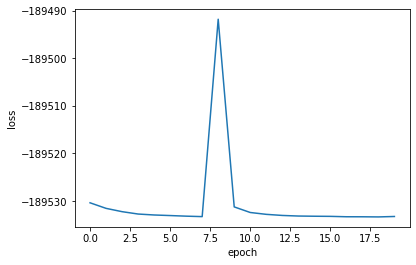

In [13]:
x = [i for i in range(0, len(loss_tracker))]

plt.plot(x, loss_tracker)
plt.xlabel('epoch')
plt.ylabel('loss')

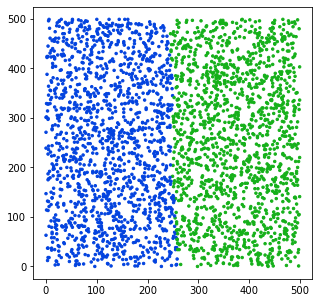

In [14]:
topic_probs, best_topic = slda.get_topic_assignments(phi_hat, pi_hat, document_locs, input_arr, n_docs, c, assignments, sigma, n_topics)
val, count = torch.unique(best_topic, return_counts=True)

colors = ['#15b01a','#0343df', '#ff81c0', '#f97306', '#653700']
color_dict = dict(zip(val.tolist(), colors))
color_assigments = [color_dict[j] for j in best_topic.tolist()]

fig_name = '_'.join((f'{PATH_TO_MODELS}/{DATASET_NAME}_{EXPERIMENT_NAME}',
                                f'latentDim={latent_size}',
                                f'lr={lr}',
                                f'topics={n_topics}',
                                f'docs={n_docs}',
                                f'vocab={vocab_size}',
                                f'sigma={sigma}')) + '.pdf'

fig, ax = plt.subplots(1,1, figsize=(5,5))
ax.scatter(x=points[:, 0], y = points[:, 1], c=color_assigments, s=6)
plt.savefig(fig_name)
plt.show()

In [16]:
loc_df['model_topic'] = best_topic
loc_df['ground_truth'] = y
loc_df['renamed_model_topic'] = np.where(best_topic==1, 0, 1)

loc_df.head()

,x,y,model_topic,ground_truth,renamed_model_topic
0,16.0,58.0,1.0,0,0
1,46.0,473.0,1.0,0,0
2,113.0,142.0,1.0,0,0
3,58.0,401.0,1.0,0,0
4,144.0,73.0,1.0,0,0


In [26]:
loc_df['model_topic'] = best_topic
loc_df['ground_truth'] = y
loc_df['renamed_model_topic'] = np.where(best_topic==1, 0, 1)

n_correct_left = np.sum(loc_df[loc_df['x'] <= 250]['model_topic'])
n_correct_right = np.sum(loc_df[loc_df['x'] > 250]['renamed_model_topic'])

(n_correct_left+n_correct_right)/n_cells

0.9913333333333333

In [19]:
loc_df['ground_truth'].unique()

array([0, 1, 2])

## Case 3 - Gradient of density

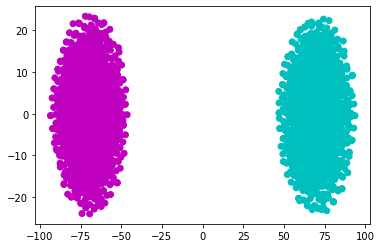

In [3]:
#Make dataset with underlying structure

n_cells = 3000
n_classes = 2 
n_genes = 200
n_informative = 20

means, variances = sim.generate_means(n_genes, n_informative)
X, y = sim.generate_data(n_cells, n_genes, n_classes, means, variances)

sim.visualize_clusters(X, y, n_classes, filename='../results/case3_embedding.pdf')


# Make spatial patterns

# Set image dimensions
x_max = 500
y_max = 500



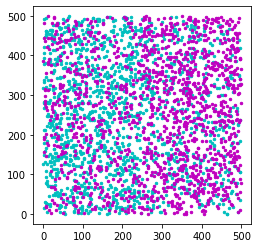

In [4]:
n_typeA = np.where(y == 0)[0].shape[0]
n_typeB = np.where(y == 1)[0].shape[0]

cells_to_scatter = 1000 #these will be of a type but not restricted to their zone

typeA_x = np.random.randint(0, x_max/2, size = (n_typeA-cells_to_scatter, 1))
typeA_x_2 = np.random.randint(0, x_max, size = (cells_to_scatter, 1))
typeA_x = np.concatenate([typeA_x, typeA_x_2], axis=0)
typeA_y = np.random.randint(0, y_max, size = (n_typeA, 1))
A_locs = np.concatenate([typeA_x, typeA_y], axis=1)

typeB_x = np.random.randint(x_max/2, x_max, size = (n_typeB-cells_to_scatter, 1))
typeB_x_2 = np.random.randint(0, x_max, size = (cells_to_scatter, 1))
typeB_x = np.concatenate([typeB_x, typeB_x_2], axis=0)

typeB_y = np.random.randint(0, y_max, size = (n_typeB, 1))
B_locs = np.concatenate([typeB_x, typeB_y], axis=1)

A_idx, = np.where(y==0)
B_idx, = np.where(y==1)


# Visualize pattern
fig, ax = plt.subplots()
ax.scatter(A_locs[:, 0], A_locs[:, 1], c='c', s=6)
ax.scatter(B_locs[:, 0], B_locs[:, 1], c='m', s=6)
ax.set_aspect('equal')
plt.savefig('../results/case3.pdf')
plt.show()

In [29]:
locs = np.zeros((n_cells, 2))

for i in range(0, len(A_idx)):
    j = A_idx[i]
    locs[j, :] = A_locs[i, :]

for i in range(0, len(B_idx)):
    j = B_idx[i]
    locs[j, :] = B_locs[i, :]

loc_df = pd.DataFrame(locs, columns=['x', 'y'])

# export data for calico comparison

gene_names = ['gene_' + str(i) for i in range(1, n_genes + 1)]

X_df = pd.DataFrame(X, columns=gene_names)
bool_arr = [True for x in range(0, len(X_df))]
export_df = pd.concat([loc_df['x'], loc_df['y'], pd.DataFrame(bool_arr, columns=['anchor']), X_df], axis = 1)
export_df.to_csv('../data/simulated/Case3_GeneExpression_Pos.csv')
pd.DataFrame(y, columns = ['cell_type']).to_csv('../data/simulated/Case3_TypeAssignments.csv')



In [30]:
test_frac = 0.15
#test_size = int(np.round(test_frac * puck_data.X.shape[0]))
test_size = int(np.round(test_frac * X.shape[0]))
#data = torch.tensor(puck_data.X, dtype=torch.float32)a
data = torch.tensor(X, dtype=torch.float32)
dataset = torch.utils.data.TensorDataset(data)
test_data, train_data = torch.utils.data.random_split(dataset, [test_size, data.shape[0]-test_size])

batch_size = 64
train_loader = torch.utils.data.DataLoader(train_data, batch_size = batch_size, shuffle = True)

In [31]:
points = spatialdata_preprocessing.make_points_arr(loc_df, 'x', 'y')
distance_matrix = spatial.distance.cdist(points, points)

# Constant model params
vocab_size = 10 #best = [75,5,20,50]
n_topics = 2
sigma = 75
n_docs = 200
n_imgs = 1

alpha = torch.ones((n_topics,))/n_topics #uniform priors
beta = torch.ones(vocab_size)/vocab_size

ids = np.zeros((points.shape[0],1))
c = np.concatenate([ids, points], axis=1)

document_locs, docs_in_img = slda.initialize_documents_spatialdata(c, n_docs, n_imgs) #I think this makes sense to fix across training epochs?

In [32]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

n_genes = X.shape[1]
latent_size = 4
net = VAE((1, n_genes), latent_size = latent_size)
net.to(device)

lr = 0.02 #set VAE learning rate

In [33]:
PATH_TO_MODELS = '../results'
DATASET_NAME = 'simulated200'
EXPERIMENT_NAME = 'Case3_Sep07'

save_name = '_'.join((f'{PATH_TO_MODELS}/{DATASET_NAME}_{EXPERIMENT_NAME}',
                                f'latentDim={latent_size}',
                                f'lr={lr}',
                                f'topics={n_topics}',
                                f'docs={n_docs}',
                                f'vocab={vocab_size}',
                                f'sigma={sigma}')) + '.pt'


In [34]:
loss_tracker = []

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, net.parameters()), lr=lr, weight_decay = 0.0001)

def adjust_lr(optimizer, decay_rate=0.95):
    for param_group in optimizer.param_groups:
        param_group['lr'] *= decay_rate

retrain = True
'''if os.path.exists(save_name):
    print("Model parameters have already been trained before. Retrain ? (y/n)")
    ans = input()
    if not (ans == 'y'):
        checkpoint = torch.load(save_name, map_location = device)
        net.load_state_dict(checkpoint["net"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        for g in optimizer.param_groups:
            g['lr'] = lr
'''
max_epochs = 20
slda_loss = 0 # Set the initial SLDA loss. 
early_stop = EarlyStop(patience = 20, save_name = save_name)
net = net.to(device)

print("training on ", device)
for epoch in range(max_epochs):

    train_loss, n, start = 0.0, 0, time.time()
    
    for jj in range(0, 5):
        for X, in tqdm.tqdm(train_loader, ncols = 50):
        #for X, in train_loader:
            X = X.to(device)
            X_hat, mean, logvar = net(X)

            l = loss(X, X_hat, mean, logvar, slda_loss).to(device)
            optimizer.zero_grad()
            l.backward()
            optimizer.step()

            train_loss += l.cpu().item()
            n += X.shape[0]

        train_loss /= n

    #NOW NEED TO USE THIS PARAMETER SETTING TO DO SLDA...

    #ENCODE DATASET WITH PARTIALLY TRAINED VAE
    decoded_z, mean, logvar = net.forward(data) #embed to latent distrobution
    X_temp = net.sampling(mean, logvar)           #sample within latent distrib

    #USE EMBEDDED DATA TO RUN SLDA 

    #Setup here will have to happen every time :/ 
    featurized_data = spatialdata_preprocessing.calculate_weighted_markers(distance_matrix, X_temp.detach().numpy(), sigma=sigma)
    kmeans, assignments = spatialdata_preprocessing.cluster_descriptors(featurized_data, vocab_size)
    input_arr = slda.build_input_word_array(assignments, c)
    
    
    z, docs, n_dk, n_kw, n_d, n_k = slda.initialize_model(input_arr, n_imgs, n_docs, n_topics, vocab_size)
   

    pi_hat, phi_hat, n_dk, n_kw, n_k, n_d, docs, z, slda_loss = slda.train_model(input_arr, document_locs, docs_in_img, n_imgs, n_docs, n_topics, vocab_size, z, docs, n_dk, n_kw, n_d, n_k, alpha, beta, sigma, n_epochs=10, return_loss=True) #train the SLDA, need to add in a return of the final loss here. 

    
    print('epoch %d, train loss %.4f , time %.1f sec'
          % (epoch, train_loss, time.time() - start))
    
    loss_tracker.append(train_loss)
    adjust_lr(optimizer)
    
    if (early_stop(train_loss, net, optimizer)):
        break

checkpoint = torch.load(early_stop.save_name)
net.load_state_dict(checkpoint["net"])

training on  cpu


100%|█████████████| 40/40 [00:00<00:00, 60.06it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 9.211627960205078
1 9.187286376953125
2 8.89495849609375
3 7.784822463989258
4 6.171148300170898
5 5.892271518707275
6 5.836528778076172
7 5.864250183105469
8 5.837416648864746
9 5.833031177520752
epoch 0, train loss -180185.4879 , time 21.6 sec


100%|█████████████| 40/40 [00:00<00:00, 62.04it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 9.63543701171875
1 9.566655158996582
2 9.437880516052246
3 9.260590553283691
4 8.941692352294922
5 8.144039154052734
6 7.000025272369385
7 6.367358684539795
8 6.191033363342285
9 6.24030065536499
epoch 1, train loss -180187.0332 , time 20.0 sec


100%|█████████████| 40/40 [00:00<00:00, 61.00it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


... (32 outputs left out)

0 8.09762191772461
1 8.068696975708008
2 7.844525337219238
3 7.026096820831299
4 5.516695022583008
5 5.074225902557373
6 5.078685283660889
7 5.133663654327393
8 5.079011917114258
9 5.089916229248047
epoch 18, train loss -180189.4635 , time 21.1 sec
EarlyStopping counter: 8 out of 20


100%|█████████████| 40/40 [00:00<00:00, 63.75it/s]
/Users/ethan/Dropbox (MIT)/Lab/sceLDA/code/slda.py:202: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)


0 9.52466106414795
1 9.421367645263672
2 9.15453052520752
3 8.304895401000977
4 7.417820453643799
5 6.850235462188721
6 6.580825328826904
7 6.468574523925781
8 6.25875997543335
9 6.251063346862793
epoch 19, train loss -180189.4814 , time 20.4 sec
EarlyStopping counter: 9 out of 20


<All keys matched successfully>

Text(0, 0.5, 'loss')

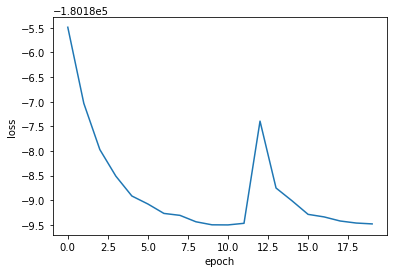

In [35]:
x = [i for i in range(0, len(loss_tracker))]

plt.plot(x, loss_tracker)
plt.xlabel('epoch')
plt.ylabel('loss')

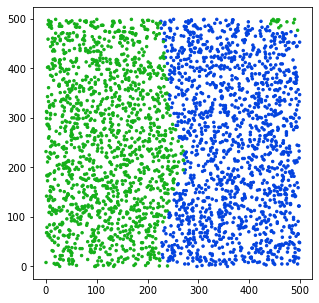

In [36]:
topic_probs, best_topic = slda.get_topic_assignments(phi_hat, pi_hat, document_locs, input_arr, n_docs, c, assignments, sigma, n_topics)
val, count = torch.unique(best_topic, return_counts=True)

colors = ['#15b01a','#0343df', '#ff81c0', '#f97306', '#653700']
color_dict = dict(zip(val.tolist(), colors))
color_assigments = [color_dict[j] for j in best_topic.tolist()]

fig_name = '_'.join((f'{PATH_TO_MODELS}/{DATASET_NAME}_{EXPERIMENT_NAME}',
                                f'latentDim={latent_size}',
                                f'lr={lr}',
                                f'topics={n_topics}',
                                f'docs={n_docs}',
                                f'vocab={vocab_size}',
                                f'sigma={sigma}')) + '.pdf'

fig, ax = plt.subplots(1,1, figsize=(5,5))
ax.scatter(x=points[:, 0], y = points[:, 1], c=color_assigments, s=6)
plt.savefig(fig_name)
plt.show()

In [40]:
loc_df['model_topic'] = best_topic
loc_df['ground_truth'] = y
loc_df['renamed_model_topic'] = np.where(best_topic==1, 0, 1)

n_correct_left = np.sum(loc_df[loc_df['x'] <= 250]['model_topic'])
n_correct_right = np.sum(loc_df[loc_df['x'] > 250]['renamed_model_topic'])

1- (n_correct_left+n_correct_right)/n_cells

0.9646666666666667

(0.0, 500.0)

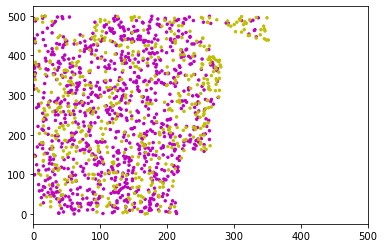

In [81]:

idx, = np.where(best_topic == 0) #same as A_idx or B_idx

color_arr = []
for i in idx:
    if i in A_idx:
        color_arr.append('m')
    else:
        color_arr.append('y')

plt.scatter(points[idx,0], points[idx, 1], s=6, c=color_arr)
plt.xlim(0,500)


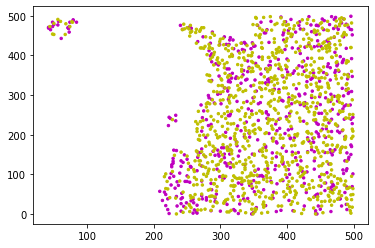

In [82]:

idx, = np.where(best_topic == 1) #same as A_idx or B_idx

color_arr = []
for i in idx:
    if i in A_idx:
        color_arr.append('m')
    else:
        color_arr.append('y')

plt.scatter(points[idx,0], points[idx, 1], s=6, c=color_arr)



tensor(7.1475)